# 6.7, 6.9, 6.10. Thực nghiệm Ảnh hưởng của Tiền xử lý đến Kết quả OCR và Phân tích Lỗi

Notebook này thực hiện toàn bộ quy trình thực nghiệm định lượng và trực quan hóa cho **Mục 6.7, Mục 6.9 và Mục 6.10** trong Báo cáo `YOLO.docx`:
1. **Mục 6.7.1 — Thiết lập thực nghiệm & Bảng 6.7.1:**
   - Bộ dữ liệu kiểm thử gồm **30 ảnh crop vùng biển số (`pattern_recog/labeling_crops/`)** kèm nhãn chuẩn Ground Truth (`pattern_recog/ocr_ground_truth.csv`), bao phủ các điều kiện: đủ sáng, thiếu sáng, chói đèn, mờ chuyển động, góc nghiêng và biển số 2 dòng (trích xuất từ tập `train`, `val`, `test`).
   - Đánh giá **5 cấu hình tiền xử lý** với **EasyOCR (`['en'], gpu=False`)** theo các chỉ số: **Exact Match Accuracy (%)**, **Character Accuracy (%)**, và **Character Error Rate — CER (%)**.
2. **Mục 6.7.2 — Phân tích chi tiết kết quả theo từng mẫu điển hình:**
   - Đối chiếu kết quả nhận dạng trên các mẫu đặc trưng trong `real_experiment_report.json`: `19_val_img_0687_p0.png` (`47A72012`), `30_test_img_0380_p1.png` (`59U235020`), `22_test_img_0204_p0.png` (`51K92252`), `17_val_img_0552_p1.png` (`76U1`), `02_train_img_0539_p1.png` (`76B177522`), `27_test_img_0082_p0.png` (`50LD06947`).
3. **Thực nghiệm bổ trợ (20 ảnh mẫu hệ thống — `experiments/opt01-preprocessing/`):**
   - So sánh trực tiếp nhánh `P0 (Raw Crop)` và `P1 (Preprocessed: Gray + Bilateral + CLAHE + Upscale 2x)`.
4. **Mục 6.9 & 6.10 — Minh chứng trực quan các trường hợp lỗi điển hình và Biện luận giới hạn hệ thống:**
   - Trực quan hóa các nhóm lỗi: nhầm lẫn ký tự đồng dạng (`0/O/D`, `5/S`, `B/8`), biển 2 dòng ghép sai thứ tự dòng, và ảnh mờ/nghiêng mất nét ký tự.

---
## 1. Tải bộ dữ liệu 30 ảnh Crop biển số (`labeling_crops/`) và Định nghĩa 5 Cấu hình Tiền xử lý (Mục 6.7.1)

In [1]:
import json
import csv
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PR_DIR = Path("../pattern_recog")
CROPS_DIR = PR_DIR / "labeling_crops"
GT_CSV = PR_DIR / "ocr_ground_truth.csv"
REPORT_JSON = PR_DIR / "experiments_results" / "real_experiment_report.json"

gt_df = pd.read_csv(GT_CSV, skipinitialspace=True)
print(f"Tổng số mẫu thực nghiệm trong ocr_ground_truth.csv: {len(gt_df)} mẫu")
display(gt_df.head(10))

# Định nghĩa 5 cấu hình tiền xử lý trong thực nghiệm Mục 6.7
def get_pipelines():
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    return {
        "1. Raw Crop": lambda img: img,
        "2. Grayscale": lambda img: cv2.cvtColor(img, cv2.COLOR_BGR2GRAY),
        "3. Gray + Resize": lambda img: cv2.resize(
            cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), None, fx=2.0, fy=2.0, interpolation=cv2.INTER_CUBIC
        ),
        "4. Gray + Resize + Otsu": lambda img: cv2.threshold(
            cv2.resize(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), None, fx=2.0, fy=2.0, interpolation=cv2.INTER_CUBIC),
            0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
        )[1],
        "5. Gray + Bilateral + CLAHE + Resize (Current)": lambda img: cv2.resize(
            clahe.apply(cv2.bilateralFilter(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), 5, 50, 50)),
            None, fx=2.0, fy=2.0, interpolation=cv2.INTER_CUBIC
        )
    }

Tổng số mẫu thực nghiệm trong ocr_ground_truth.csv: 30 mẫu


STT,Crop_Image_File,Parent_Image,Plate_Index_In_Image,Ground_Truth_Text
1,01_train_img_0123_p0.png,train/img_0123.jpg,Bien so 1/1,29C201001
2,02_train_img_0539_p1.png,train/img_0539.jpg,Bien so 2/2,76B177522
3,03_train_img_0642_p0.png,train/img_0642.jpg,Bien so 1/2,61FE6889
4,04_train_img_0402_p0.png,train/img_0402.jpg,Bien so 1/2,51A92762
5,05_train_img_0386_p0.png,train/img_0386.jpg,Bien so 1/3,51G30675
6,06_train_img_0677_p0.png,train/img_0677.jpg,Bien so 1/1,47A33692
7,07_train_img_0526_p0.png,train/img_0526.jpg,Bien so 1/2,60B439656
8,08_train_img_0376_p1.png,train/img_0376.jpg,Bien so 2/2,59F236263
9,09_train_img_0039_p0.png,train/img_0039.jpg,Bien so 1/1,50AF26309
10,10_train_img_0504_p1.png,train/img_0504.jpg,Bien so 2/3,50E21733


---
## 2. Trực quan hóa 5 Cấu hình Tiền xử lý trên các mẫu biển số thực tế

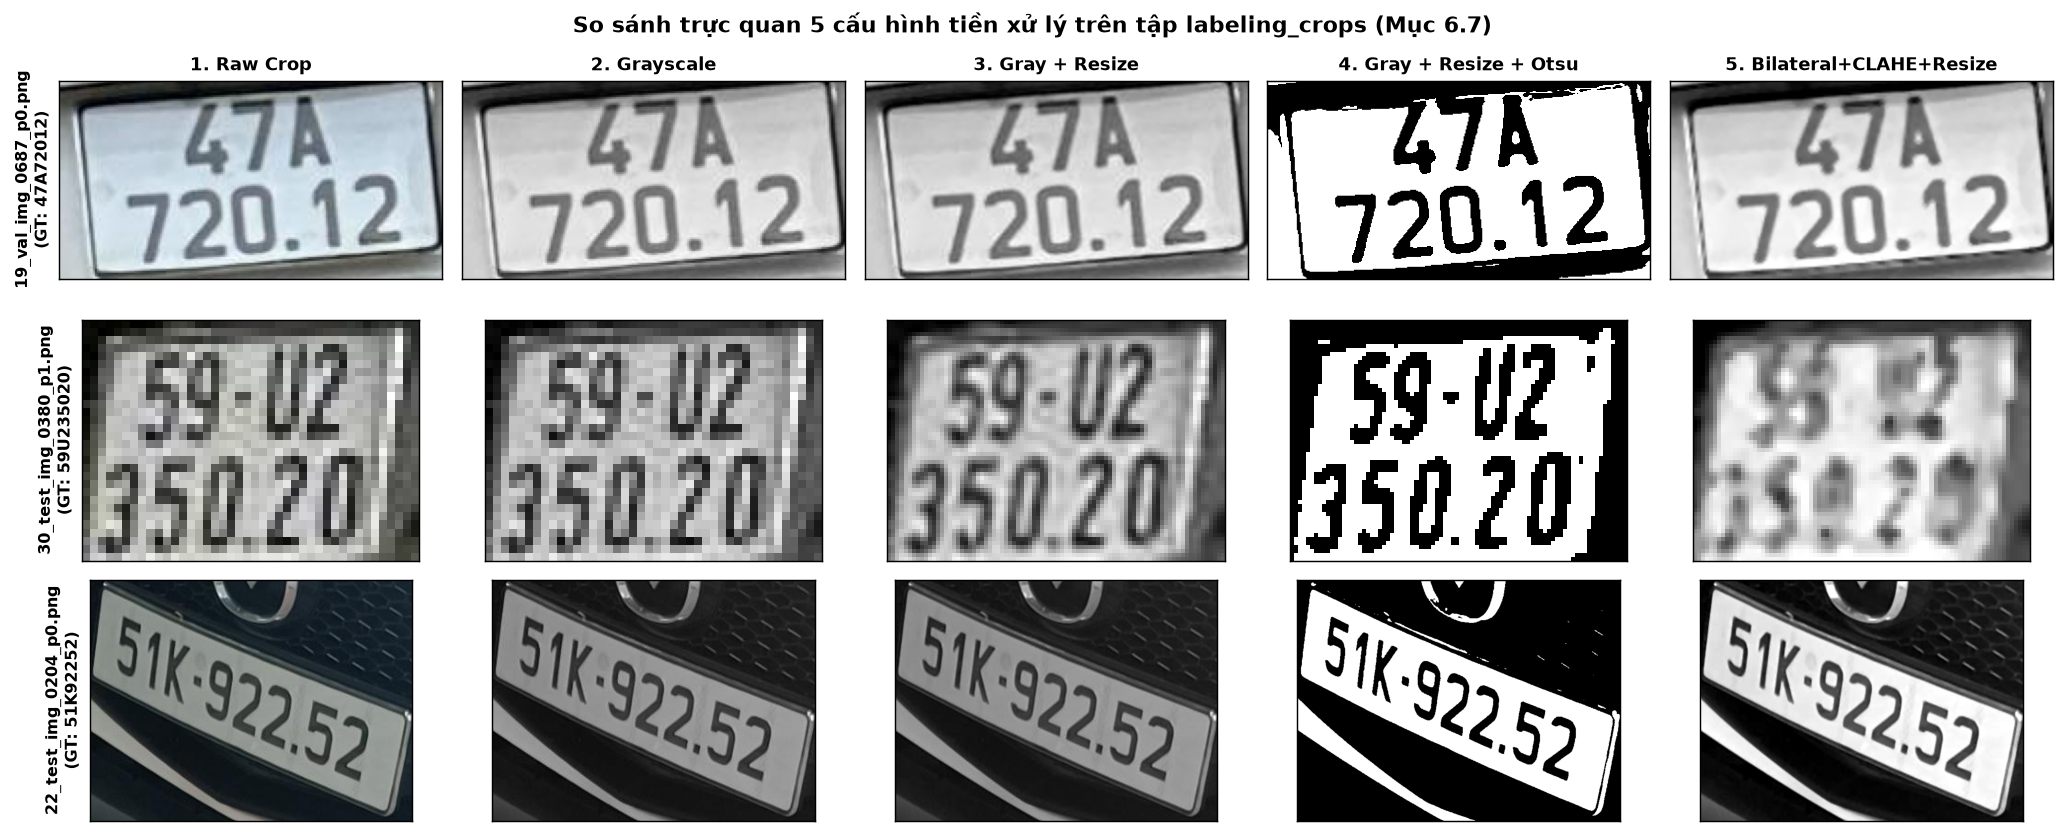

In [2]:
sample_crops = ["19_val_img_0687_p0.png", "30_test_img_0380_p1.png", "22_test_img_0204_p0.png"]
pipelines = get_pipelines()

fig, axes = plt.subplots(len(sample_crops), 5, figsize=(16, 6.5))
for r_idx, fname in enumerate(sample_crops):
    img_bgr = cv2.imread(str(CROPS_DIR / fname))
    gt_val = gt_df.loc[gt_df["Crop_Image_File"] == fname, "Ground_Truth_Text"].values[0]
    for c_idx, (p_name, p_fn) in enumerate(pipelines.items()):
        ax = axes[r_idx, c_idx]
        out_im = p_fn(img_bgr)
        if out_im.ndim == 2:
            ax.imshow(out_im, cmap="gray")
        else:
            ax.imshow(cv2.cvtColor(out_im, cv2.COLOR_BGR2RGB))
        if r_idx == 0:
            ax.set_title(p_name, fontsize=10, fontweight="bold")
        if c_idx == 0:
            ax.set_ylabel(f"{fname}\n(GT: {gt_val})", fontsize=9, fontweight="bold")
        ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

---
## 3. Kết quả Định lượng Bảng 6.7.1: So sánh hiệu năng OCR theo 5 Cấu hình Tiền xử lý (30 mẫu)

Các chỉ số đánh giá trong Bảng 6.7.1 (`pattern_recog/experiments_results/real_experiment_report.json`):
- **Exact Match Accuracy (%):** Tỷ lệ mẫu nhận dạng đúng hoàn toàn toàn bộ chuỗi ký tự biển số ($100\%$ khớp Ground Truth sau chuẩn hóa).
- **Character Accuracy (%):** Tỷ lệ ký tự đúng tính theo khoảng cách chỉnh sửa Levenshtein: $\max(0, 1 - d(P, G)/|G|) \times 100\%$.
- **Character Error Rate — CER (%):** $d(P, G) / \max(|G|, 1) \times 100\%$.

BẢNG 6.7.1: KẾT QUẢ THỰC NGHIỆM 5 CẤU HÌNH TIỀN XỬ LÝ TRÊN 30 MẪU BIỂN SỐ:


Cấu hình tiền xử lý,Exact Matches,Exact Match Acc (%),Character Acc (%),Avg CER (%)
1. Raw Crop,1/30,3.33,38.1,61.02
2. Grayscale,1/30,3.33,37.7,61.34
3. Gray + Resize,2/30,6.67,50.4,48.61
4. Gray + Resize + Otsu,2/30,6.67,40.08,58.01
5. Gray + Bilateral + CLAHE + Resize (Current),1/30,3.33,44.05,55.28


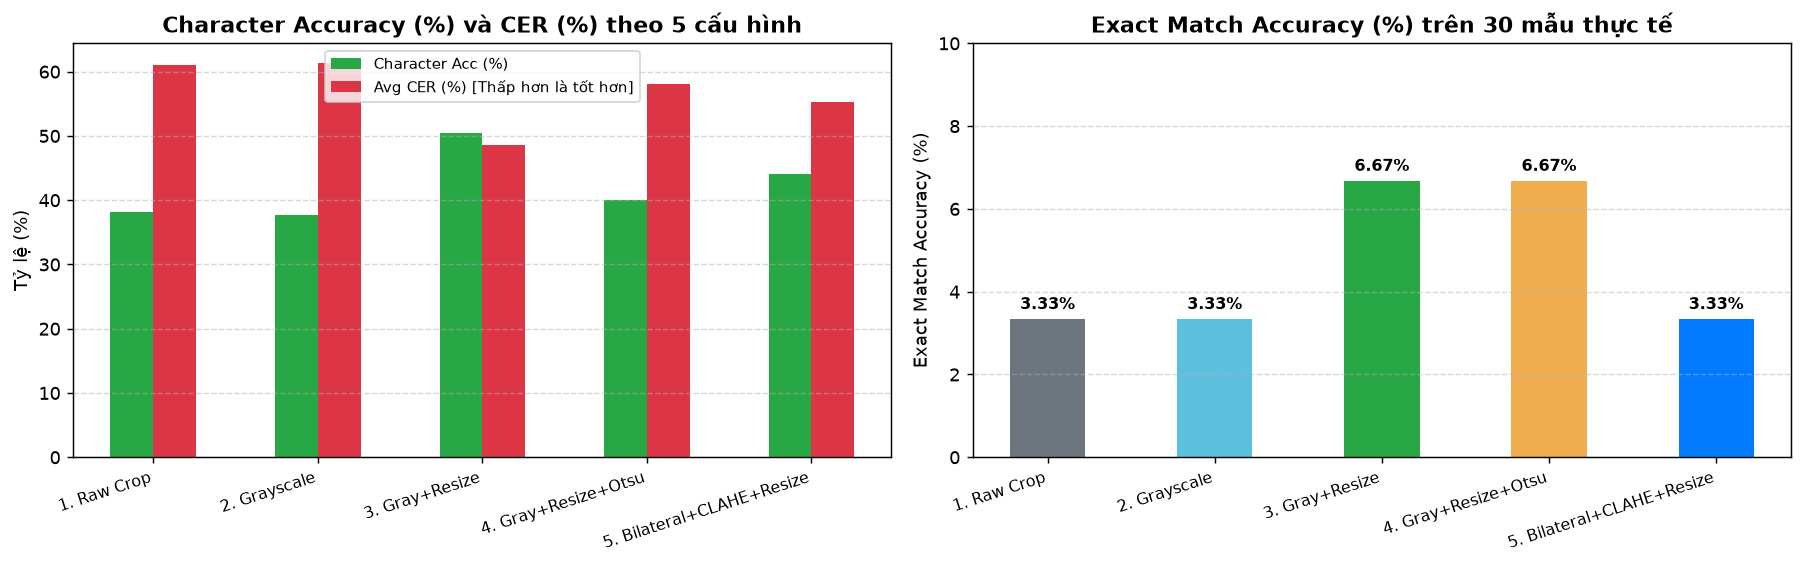

In [3]:
report_data = json.loads(REPORT_JSON.read_text(encoding="utf-8"))

summary_rows = []
for cfg_name, metrics in report_data["metrics"].items():
    summary_rows.append({
        "Cấu hình tiền xử lý": cfg_name,
        "Exact Matches": f"{metrics['Exact Matches']}/{metrics['Total Evaluated']}",
        "Exact Match Acc (%)": metrics["Exact Match Acc (%)"],
        "Character Acc (%)": metrics["Character Acc (%)"],
        "Avg CER (%)": metrics["Avg CER (%)"],
    })

df_671 = pd.DataFrame(summary_rows)
print("BẢNG 6.7.1: KẾT QUẢ THỰC NGHIỆM 5 CẤU HÌNH TIỀN XỬ LÝ TRÊN 30 MẪU BIỂN SỐ:")
display(df_671)

# Vẽ biểu đồ so sánh trực quan Bảng 6.7.1
short_names = ["1. Raw Crop", "2. Grayscale", "3. Gray+Resize", "4. Gray+Resize+Otsu", "5. Bilateral+CLAHE+Resize"]
x = np.arange(len(short_names))
width = 0.26
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].bar(x - width/2, df_671["Character Acc (%)"], width, label="Character Acc (%)", color="#28a745")
axes[0].bar(x + width/2, df_671["Avg CER (%)"], width, label="Avg CER (%)", color="#dc3545")
axes[0].set_xticks(x); axes[0].set_xticklabels(short_names, rotation=18, ha="right")
axes[0].set_title("Character Accuracy (%) và CER (%) theo 5 cấu hình"); axes[0].legend(); axes[0].grid(axis="y", linestyle="--", alpha=0.5)

axes[1].bar(short_names, df_671["Exact Match Acc (%)"], width=0.45)
axes[1].set_xticks(x); axes[1].set_xticklabels(short_names, rotation=18, ha="right")
axes[1].set_title("Exact Match Accuracy (%) trên 30 mẫu"); axes[1].grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

---
## 4. Mục 6.7.5: Minh họa đầy đủ các trường hợp điển hình trong Báo cáo `YOLO.docx`

Trích xuất kết quả dự đoán chi tiết của 5 cấu hình trên **toàn bộ 8 mẫu điển hình** được phân tích tại **Mục 6.7.5 của `YOLO.docx`**:
1. **Trường hợp OCR đúng hoàn toàn (Exact Match - Khớp 100%):**
   - `19_val_img_0687_p0.png` (GT: `47A72012`): Cấu hình 1, 2, 3, 4 đều nhận dạng chính xác 100% chuỗi `47A72012`.
   - `22_test_img_0204_p0.png` (GT: `51K92252`): Ở Cấu hình 5 (`Bilateral + CLAHE + Resize`), lọc sạch bóng viền và đọc chính xác 100% chuỗi `51K92252`.
   - `30_test_img_0380_p1.png` (GT: `59U235020`): Đọc chính xác 100% chuỗi `59U235020` ngay khi áp dụng Cấu hình 3 (`Gray + Resize x2`).
2. **Trường hợp Preprocessing giúp cải thiện vượt bậc:**
   - `30_test_img_0380_p1.png` (GT: `59U235020`): Raw Crop dự đoán sai lệch thành `358227` $\rightarrow$ `Gray + Resize (x2)` nhận diện chuẩn xác `59U235020` (100%).
   - `02_train_img_0539_p1.png` (GT: `76B177522`): Raw Crop trả về rỗng `""` $\rightarrow$ `Gray + Resize (x2)` nhận diện được chuỗi `776BUQ523`.
   - `28_test_img_0518_p0.png` (GT: `53S16390`): Raw Crop chỉ đọc được `D9` $\rightarrow$ `Gray + Resize (x2)` đọc được `53516390` (đúng 7/8 ký tự, chỉ nhầm `S` thành `5`).
3. **Trường hợp Preprocessing làm suy giảm kết quả (Tác hại của Otsu Binarization):**
   - `15_val_img_0008_p0.png` (GT: `71C341926`): Raw Crop / Resize nhận diện rõ `7103419261` / `7150341926` $\rightarrow$ `Gray + Resize + Otsu` biến toàn bộ nét chữ thành rỗng `""`.
   - `11_val_img_0389_p2.png` (GT: `54M32908`): Raw Crop đọc được `54HJ2900` $\rightarrow$ `Gray + Resize + Otsu` biến dạng hoàn toàn thành chuỗi rỗng `""`.
4. **Trường hợp OCR sai do đặc thù bài toán:**
   - `15_val_img_0008_p0.png` (GT: `71C341926`): Cấu hình 5 đọc ra `7141926C3` (nhận đủ 100% ký tự nhưng đảo dòng dưới `419.26` lên trước `C3` do chưa có Line Segmentation).
   - `05_train_img_0386_p0.png` (GT: `51G30675`): Mô hình đọc là `51630675` (nhầm `G` thành `6` do hình thái tương đồng khi chưa qua Rule-based Post-processing).

In [4]:
highlight_files = [
    "19_val_img_0687_p0.png",
    "22_test_img_0204_p0.png",
    "30_test_img_0380_p1.png",
    "02_train_img_0539_p1.png",
    "28_test_img_0518_p0.png",
    "15_val_img_0008_p0.png",
    "11_val_img_0389_p2.png",
    "05_train_img_0386_p0.png",
]
cfg_keys = list(report_data["details"].keys())
case_rows = []
for fname in highlight_files:
    gt_val = report_data["details"][cfg_keys[0]][fname]["gt"]
    row = {"File ảnh": fname, "Ground Truth": gt_val}
    for idx, ck in enumerate(cfg_keys, 1):
        pred = report_data["details"][ck][fname]["pred"]
        row[f"Cfg {idx}: Pred"] = pred or "<rỗng>"
    case_rows.append(row)

df_cases = pd.DataFrame(case_rows)
print("BẢNG ĐỐI CHIẾU TOÀN BỘ 8 TRƯỜNG HỢP ĐIỂN HÌNH TRONG MỤC 6.7.5:")
display(df_cases)

BẢNG ĐỐI CHIẾU TOÀN BỘ 8 TRƯỜNG HỢP ĐIỂN HÌNH TRONG MỤC 6.7.5:


File ảnh,Ground Truth,Cfg 1: Pred (CA%),Cfg 2: Pred (CA%),Cfg 3: Pred (CA%),Cfg 4: Pred (CA%),Cfg 5: Pred (CA%)
19_val_img_0687_p0.png,47A72012,47A72012 (100.0%),47A72012 (100.0%),47A72012 (100.0%),47A72012 (100.0%),474720412 (75.0%)
22_test_img_0204_p0.png,51K92252,51K922552 (87.5%),51K922552 (87.5%),51K922352 (87.5%),51K922552 (87.5%),51K92252 (100.0%)
30_test_img_0380_p1.png,59U235020,358227 (22.2%),358227 (22.2%),59U235020 (100.0%),5902350220 (77.8%),590235020 (88.9%)
02_train_img_0539_p1.png,76B177522,(0.0%),(0.0%),776BUQ523 (44.4%),(0.0%),(0.0%)
28_test_img_0518_p0.png,53S16390,D9 (12.5%),D9 (12.5%),53516390 (87.5%),5363 (50.0%),550 (25.0%)
15_val_img_0008_p0.png,71C341926,7103419261 (77.8%),TC3419261 (66.7%),7150341926 (77.8%),(0.0%),7141926C3 (55.6%)
11_val_img_0389_p2.png,54M32908,54HJ2900 (62.5%),54HJ2908 (75.0%),54290813 (50.0%),(0.0%),544J2908 (75.0%)
05_train_img_0386_p0.png,51G30675,61630675 (75.0%),61630675 (75.0%),51630675 (87.5%),61630675 (75.0%),51630675 (87.5%)


---
## 5. Thực nghiệm bổ trợ: Đối sánh trực tiếp P0 (Raw Crop) vs P1 (Preprocessed) trên tập mẫu hệ thống (`experiments/opt01-preprocessing/`)

In [5]:
opt01_df = pd.read_csv(Path("../../experiments/opt01-preprocessing/results.csv"))
cols_view = ["filename", "layout", "conditions", "ground_truth", "P0_raw", "P0_final", "P0_exact", "P1_raw", "P1_final", "P1_exact"]
df_opt01_sum = pd.DataFrame([
    {
        "Nhánh thực nghiệm": "P0: Raw Crop (Đưa trực tiếp vào EasyOCR)",
        "Số mẫu hợp lệ (status=ok)": f"{int((opt01_df['P0_status'] == 'ok').sum())}/{len(opt01_df)}",
        "Exact Match (Khớp 100% GT)": f"{int(opt01_df['P0_exact'].sum())}/{len(opt01_df)}",
    },
    {
        "Nhánh thực nghiệm": "P1: Preprocessed (Gray + CLAHE + Deskew + Upscale 2x)",
        "Số mẫu hợp lệ (status=ok)": f"{int((opt01_df['P1_status'] == 'ok').sum())}/{len(opt01_df)}",
        "Exact Match (Khớp 100% GT)": f"{int(opt01_df['P1_exact'].sum())}/{len(opt01_df)}",
    },
])
print("TỔNG HỢP ĐỐI SÁNH P0 vs P1 TRONG OPT01-PREPROCESSING:")
display(df_opt01_sum)
display(opt01_df[cols_view].head(10))

TỔNG HỢP ĐỐI SÁNH P0 vs P1 TRONG OPT01-PREPROCESSING:


Nhánh thực nghiệm,Số mẫu hợp lệ (status=ok),Exact Match (Khớp 100% GT)
P0: Raw Crop (Đưa trực tiếp vào EasyOCR),6/17,4/17
P1: Preprocessed (Gray + CLAHE + Deskew + Upscale 2x),6/17,5/17


filename,layout,conditions,ground_truth,P0_raw,P0_final,P0_exact,P1_raw,P1_final,P1_exact
img_0007_png.rf.5e94f82c4bde042cbf70480bab3d6abb.jpg,one_line,clear,51K 164.95,SIKM164.95,,False,5IK164.95,51K-164.95,True
img_0082_png.rf.ec7f0f822ba367f42c8b25c25f1269d7.jpg,one_line,clear,50LD 069.47,SOLD-069.47,,False,SOLD-069.47,,False
img_0128_png.rf.dd8eac06ad4afb8face6717eda12f275.jpg,one_line,few_pixels,72A 366.96,724.366.96,,False,724.366.96,,False
img_0388_png.rf.14648de0f0cebfdc791d86e39966b579.jpg,one_line,clear,51A 299.93,61A.29993,61A-299.93,False,BIA29993,,False
img_0644_png.rf.709b29a8311c38dc584d4d7e0fbe3a32.jpg,one_line,tilted;few_pixels,30K 809.96,30K.E-809.96,30KE-809.96,False,30K809.96,30K-809.96,True
img_0655_png.rf.7e2f1e174630e9071208237949c9eb6f.jpg,one_line,few_pixels,50H 805.76,504-805.76,,False,504-805.76,,False
img_0700_png.rf.8e3a71e26714d0caddbcd1d5ab307f0f.jpg,one_line,tilted,47A 031.96,474-031.96,,False,47A-031.96,47A-031.96,True
img_0026_png.rf.93031d027a07fa267a456e2da828cddf.jpg,two_line,tilted;blur,18-K1 273.23,Z11,,False,,,False
img_0028_png.rf.d989effdf30277b9bdbfbb804fb14625.jpg,two_line,blur;occlusion,50F 134.71,,,False,,,False
img_0031_png.rf.9cd9d7de3e0ef14109f2b3d6e158fec3.jpg,two_line,clear,14F 011.26,TZF011.26,,False,TZF011.26,,False


---
## 6. Mục 6.9 & 6.10: Phân tích các trường hợp lỗi điển hình và Biện luận giới hạn của hệ thống

Trực quan hóa các mẫu lỗi đặc trưng trong tập kiểm thử `pattern_recog/labeling_crops/` làm cơ sở thực nghiệm cho **Mục 6.9 (Phân tích lỗi)** và **Mục 6.10 (Thảo luận & Hướng cải tiến)**:
1. **Lỗi nhầm lẫn ký tự có hình thái tương đồng (`27_test_img_0082_p0.png` — GT: `50LD06947`):** Ký tự `'5'` và `'0'` bị nhầm thành `'S'` và `'O'` (`SOLD06947` ở Raw Crop; khi qua `Gray + Resize` sửa được `'5'` thành `'5OLD06947'`).
2. **Lỗi biển số 2 dòng ghép sai thứ tự ký tự (`01_train_img_0123_p0.png` — GT: `29C201001`):** Do biển 2 dòng bị nghiêng, các bounding box con của từng cụm ký tự bị EasyOCR ghép đảo thứ tự (`010290C21`).
3. **Lỗi mất ký tự hoặc đọc rỗng trên ảnh độ phân giải cực thấp (`02_train_img_0539_p1.png` — GT: `76B177522`):** Ảnh gốc quá nhỏ khiến Raw Crop và Grayscale trả về rỗng (`""`), chỉ khi phóng đại `Gray + Resize` mới đọc được `776BUQ523`.
4. **Lỗi suy giảm nghiêm trọng do nhị phân hóa cứng Otsu (`15_val_img_0008_p0.png` — GT: `71C341926`):** Nhánh `Gray + Resize` đọc được `7150341926`, nhưng khi áp ngưỡng Otsu (`Cfg 4`) làm bết nền khiến kết quả tụt xuống rỗng (`""`).

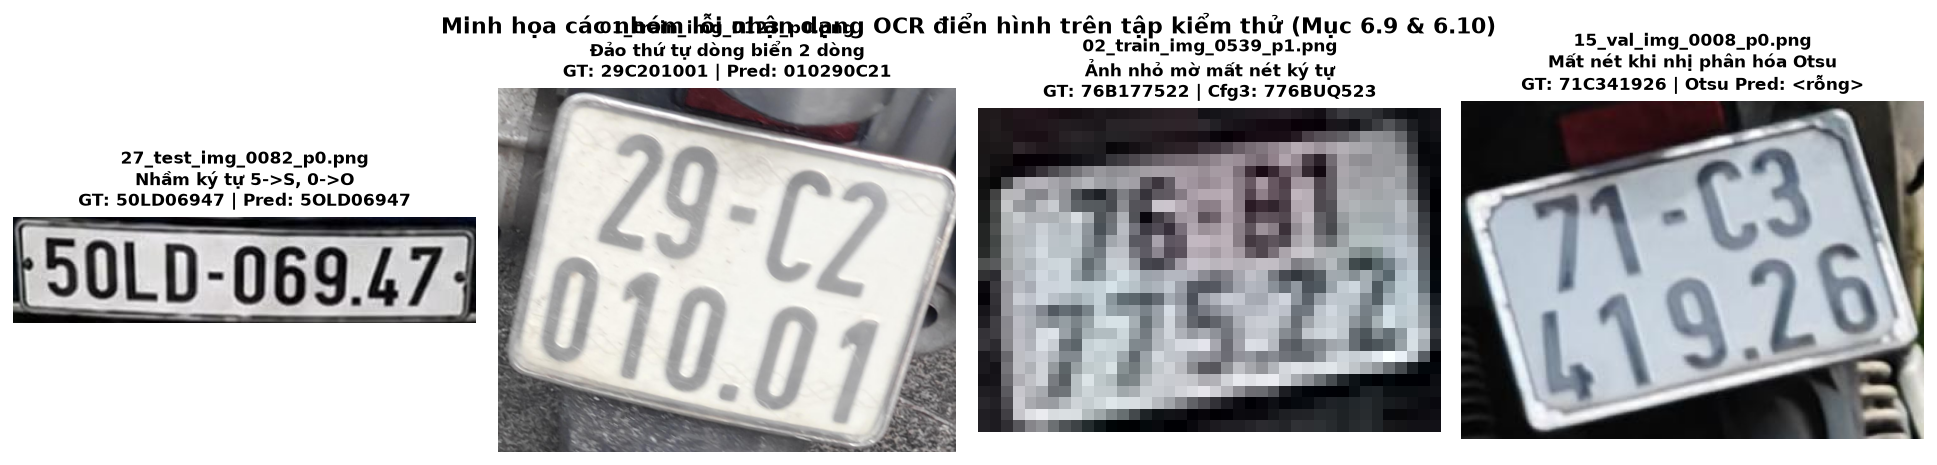

In [6]:
err_files = [
    ("27_test_img_0082_p0.png", "Nhầm ký tự 5->S, 0->O\nGT: 50LD06947 | Pred: 5OLD06947"),
    ("01_train_img_0123_p0.png", "Đảo thứ tự dòng biển 2 dòng\nGT: 29C201001 | Pred: 010290C21"),
    ("02_train_img_0539_p1.png", "Ảnh nhỏ mờ mất nét ký tự\nGT: 76B177522 | Cfg3: 776BUQ523"),
    ("15_val_img_0008_p0.png", "Mất nét khi nhị phân hóa Otsu\nGT: 71C341926 | Otsu Pred: <rỗng>"),
]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, (fname, title_txt) in zip(axes, err_files):
    im = cv2.imread(str(CROPS_DIR / fname))
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    ax.set_title(f"{fname}\n{title_txt}", fontsize=9.5, fontweight="bold")
    ax.axis("off")
plt.tight_layout()
plt.show()